# Motor Insurance Claim-Frequency Pricing: GLM vs XGBoost
Predicting how often motor insurance customers claim, on 678,013 French policies (freMTPL2). Compares the industry-standard Poisson GLM with XGBoost, explains the models with SHAP, tests whether XGBoost's gain is genuine, and tracks every model in MLflow.

## 1. Load the data
Download freMTPL2freq from OpenML: one row per policy, with the number of claims and the years insured (exposure).

In [0]:
from sklearn.datasets import fetch_openml

raw = fetch_openml(data_id=41214, as_frame=True).frame   # freMTPL2freq
print(raw.shape)
raw.head()

(678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


## 2. First look
Claim counts, exposure and overall claim frequency (claims ÷ years insured).

In [0]:
print(raw.dtypes, "\n")
print("Claim count distribution:\n", raw["ClaimNb"].value_counts().sort_index(), "\n")
print("Exposure:\n", raw["Exposure"].describe(), "\n")

freq = raw["ClaimNb"].sum() / raw["Exposure"].sum()
print(f"Portfolio claim frequency: {freq:.4f} claims per policy-year")
print(f"Policies with zero claims: {(raw['ClaimNb'] == 0).mean():.1%}")

IDpol          float64
ClaimNb          int64
Exposure       float64
Area          category
VehPower         int64
VehAge           int64
DrivAge          int64
BonusMalus       int64
VehBrand      category
VehGas          object
Density          int64
Region        category
dtype: object 

Claim count distribution:
 ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64 

Exposure:
 count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64 

Portfolio claim frequency: 0.1007 claims per policy-year
Policies with zero claims: 95.0%


Save the raw data as a Delta table so later steps don't re-download it.

In [0]:
import pandas as pd

df = raw.copy()
for col in ["Area", "VehBrand", "VehGas", "Region"]:
    df[col] = df[col].astype(str)
df["ClaimNb"] = df["ClaimNb"].astype(int)
df["IDpol"] = df["IDpol"].astype(int)

spark.sql("CREATE SCHEMA IF NOT EXISTS workspace.pricing")
spark.createDataFrame(df).write.mode("overwrite").saveAsTable("workspace.pricing.fremtpl2_raw")
print(spark.table("workspace.pricing.fremtpl2_raw").count())

678013


## 3. Clean the data
Cap claim counts at 4 and exposure at 1 year. Both had impossible values (up to 16 claims in under a year; exposure up to 2.01 years).

In [0]:
df = spark.table("workspace.pricing.fremtpl2_raw").toPandas()

n_claims_capped = (df["ClaimNb"] > 4).sum()
n_exposure_capped = (df["Exposure"] > 1).sum()

df["ClaimNb"] = df["ClaimNb"].clip(upper=4)
df["Exposure"] = df["Exposure"].clip(upper=1)

print(f"Claim counts capped at 4: {n_claims_capped} policies")
print(f"Exposure capped at 1:   {n_exposure_capped} policies")
print(f"Frequency after cleaning: {df['ClaimNb'].sum() / df['Exposure'].sum():.4f}")

spark.createDataFrame(df).write.mode("overwrite").saveAsTable("workspace.pricing.fremtpl2_clean")

Claim counts capped at 4: 9 policies
Exposure capped at 1:   1224 policies
Frequency after cleaning: 0.1006


## 4. One-way analysis
Claim frequency for each group of one factor at a time (e.g. by driver age), compared with the portfolio average.

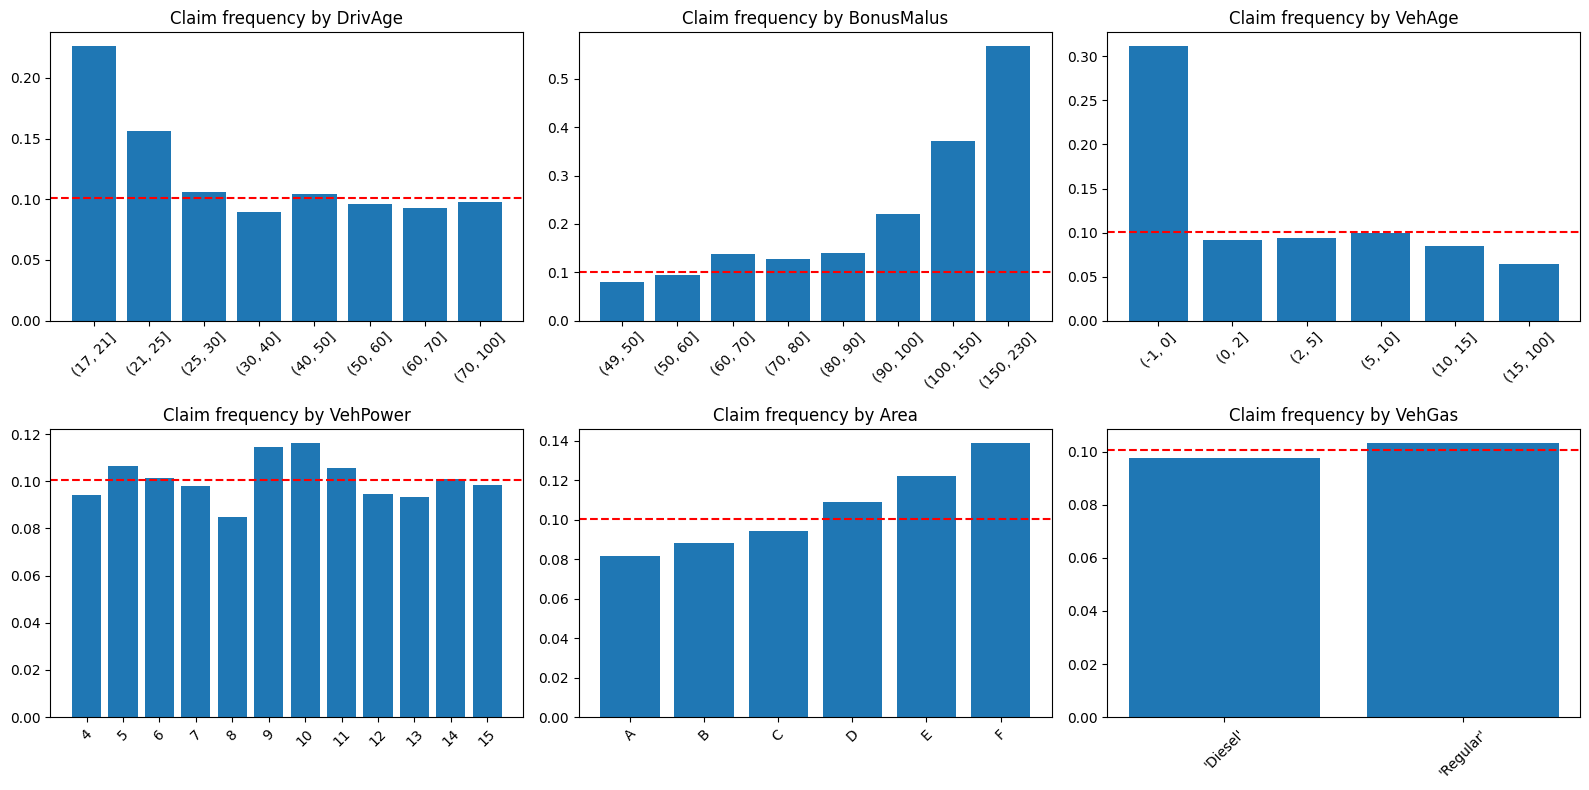

           frequency  exposure_share
DrivAge                             
(17, 21]       0.226           0.012
(21, 25]       0.156           0.033
(25, 30]       0.106           0.081
(30, 40]       0.090           0.234
(40, 50]       0.104           0.246
(50, 60]       0.096           0.211
(60, 70]       0.093           0.107
(70, 100]      0.097           0.075 

            frequency  exposure_share
BonusMalus                           
(49, 50]        0.080           0.628
(50, 60]        0.095           0.134
(60, 70]        0.139           0.074
(70, 80]        0.128           0.074
(80, 90]        0.140           0.043
(90, 100]       0.221           0.037
(100, 150]      0.371           0.010
(150, 230]      0.568           0.000 

           frequency  exposure_share
VehAge                              
(-1, 0]        0.312           0.047
(0, 2]         0.091           0.174
(2, 5]         0.094           0.201
(5, 10]        0.099           0.276
(10, 15]       0.085    

In [0]:
import pandas as pd
import matplotlib.pyplot as plt

df = spark.table("workspace.pricing.fremtpl2_clean").toPandas()
portfolio_freq = df["ClaimNb"].sum() / df["Exposure"].sum()

def one_way(col, bins=None):
    groups = pd.cut(df[col], bins) if bins else df[col]
    g = df.groupby(groups, observed=True).agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
    g["frequency"] = g["claims"] / g["exposure"]
    g["exposure_share"] = g["exposure"] / g["exposure"].sum()
    return g

views = {
    "DrivAge":    [17, 21, 25, 30, 40, 50, 60, 70, 100],
    "BonusMalus": [49, 50, 60, 70, 80, 90, 100, 150, 230],
    "VehAge":     [-1, 0, 2, 5, 10, 15, 100],
    "VehPower":   None,
    "Area":       None,
    "VehGas":     None,
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (col, bins) in zip(axes.flat, views.items()):
    g = one_way(col, bins)
    ax.bar(g.index.astype(str), g["frequency"])
    ax.axhline(portfolio_freq, color="red", linestyle="--")
    ax.set_title(f"Claim frequency by {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

for col, bins in views.items():
    print(one_way(col, bins)[["frequency", "exposure_share"]].round(3), "\n")

Check: brand-new cars show 3× the average frequency. Is it because their policies are shorter?

In [0]:
df.groupby(df["VehAge"] == 0).agg(
    policies=("IDpol", "count"),
    avg_exposure=("Exposure", "mean"),
    claims=("ClaimNb", "sum"),
)

,policies,avg_exposure,claims
VehAge,,,
False,620274,0.550827,30851
True,57739,0.289169,5205


## 5. Baseline: Poisson GLM
The industry-standard pricing model. Exposure is used as a weight; trained on 80% of policies, tested on the other 20%.

In [0]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, KBinsDiscretizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_poisson_deviance

# Target = claims per year; exposure becomes the weight
df["Frequency"] = df["ClaimNb"] / df["Exposure"]
df["BonusMalus_c"] = df["BonusMalus"].clip(upper=150)   # very thin above 150
df["LogDensity"] = np.log(df["Density"])                 # density is very skewed

# 80% to learn from, 20% held back to test on data the model has never seen
train, test = train_test_split(df, test_size=0.2, random_state=42)

glm_prep = ColumnTransformer([
    ("age_bins", KBinsDiscretizer(n_bins=10, strategy="quantile"), ["DrivAge", "VehAge"]),
    ("categories", OneHotEncoder(handle_unknown="ignore"), ["VehBrand", "VehPower", "VehGas", "Region", "Area"]),
    ("numbers", StandardScaler(), ["BonusMalus_c", "LogDensity"]),
])
glm = make_pipeline(glm_prep, PoissonRegressor(alpha=1e-4, max_iter=1000))
glm.fit(train, train["Frequency"], poissonregressor__sample_weight=train["Exposure"])

/databricks/python/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


,steps,"[('columntransformer', ...), ('poissonregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('age_bins', ...), ('categories', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Score the GLM: Poisson deviance, D² (share explained vs. an average-only model), and predicted vs. actual claims.

In [0]:
avg_freq = np.average(train["Frequency"], weights=train["Exposure"])
dumb_pred = np.full(len(test), avg_freq)

dumb_dev = mean_poisson_deviance(test["Frequency"], dumb_pred, sample_weight=test["Exposure"])
glm_dev = mean_poisson_deviance(test["Frequency"], glm.predict(test), sample_weight=test["Exposure"])

print(f"Dumb model deviance: {dumb_dev:.4f}")
print(f"GLM deviance:        {glm_dev:.4f}")
print(f"D² (share explained): {1 - glm_dev / dumb_dev:.2%}")
print(f"Predicted claims: {(glm.predict(test) * test['Exposure']).sum():,.0f}  vs actual: {test['ClaimNb'].sum():,}")

Dumb model deviance: 0.6230
GLM deviance:        0.5948
D² (share explained): 4.53%
Predicted claims: 7,191  vs actual: 7,182


## 6. XGBoost
Install XGBoost and SHAP. This restarts Python, so the next cell rebuilds the data and the GLM.

In [0]:
%pip install xgboost shap

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 81.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.3/547.3 kB 17.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.4/206.4 MB 87.6 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [shap]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, KBinsDiscretizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_poisson_deviance

df = spark.table("workspace.pricing.fremtpl2_clean").toPandas()
df["Frequency"] = df["ClaimNb"] / df["Exposure"]
df["BonusMalus_c"] = df["BonusMalus"].clip(upper=150)
df["LogDensity"] = np.log(df["Density"])
for c in ["VehBrand", "VehGas", "Region", "Area"]:
    df[c] = df[c].astype("category")

train, test = train_test_split(df, test_size=0.2, random_state=42)

glm = make_pipeline(
    ColumnTransformer([
        ("age_bins", KBinsDiscretizer(n_bins=10, strategy="quantile"), ["DrivAge", "VehAge"]),
        ("categories", OneHotEncoder(handle_unknown="ignore"), ["VehBrand", "VehPower", "VehGas", "Region", "Area"]),
        ("numbers", StandardScaler(), ["BonusMalus_c", "LogDensity"]),
    ]),
    PoissonRegressor(alpha=1e-4, max_iter=1000),
)
glm.fit(train, train["Frequency"], poissonregressor__sample_weight=train["Exposure"])

def deviance(pred):
    return mean_poisson_deviance(test["Frequency"], pred, sample_weight=test["Exposure"])

dumb_dev = deviance(np.full(len(test), np.average(train["Frequency"], weights=train["Exposure"])))
glm_dev = deviance(glm.predict(test))
print(f"GLM rebuilt. D² = {1 - glm_dev / dumb_dev:.2%}")   # should say 4.53% again

/databricks/python/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


GLM rebuilt. D² = 4.53%


Train XGBoost with a Poisson objective and early stopping, then compare with the GLM.

In [0]:
import xgboost as xgb

features = ["DrivAge", "VehAge", "VehPower", "BonusMalus", "Density", "VehBrand", "VehGas", "Region", "Area"]
fit_set, val_set = train_test_split(train, test_size=0.1, random_state=42)

xgb_model = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    enable_categorical=True,
    early_stopping_rounds=50,
)
xgb_model.fit(
    fit_set[features], fit_set["Frequency"], sample_weight=fit_set["Exposure"],
    eval_set=[(val_set[features], val_set["Frequency"])],
    sample_weight_eval_set=[val_set["Exposure"]],
    verbose=200,
)

xgb_pred = xgb_model.predict(test[features])
xgb_dev = deviance(xgb_pred)

print(f"Trees used: {xgb_model.best_iteration}")
print(f"GLM     D² = {1 - glm_dev / dumb_dev:.2%}")
print(f"XGBoost D² = {1 - xgb_dev / dumb_dev:.2%}")
print(f"XGBoost predicted claims: {(xgb_pred * test['Exposure']).sum():,.0f}  vs actual: {test['ClaimNb'].sum():,}")

[0]	validation_0-poisson-nloglik:0.38151
[200]	validation_0-poisson-nloglik:0.35900
[400]	validation_0-poisson-nloglik:0.35838
[600]	validation_0-poisson-nloglik:0.35802
[795]	validation_0-poisson-nloglik:0.35790
Trees used: 745
GLM     D² = 4.53%
XGBoost D² = 7.86%
XGBoost predicted claims: 7,170  vs actual: 7,182


## 7. Ranking risk: Lorenz curve and Gini
Do the customers each model ranks riskiest actually make most of the claims?

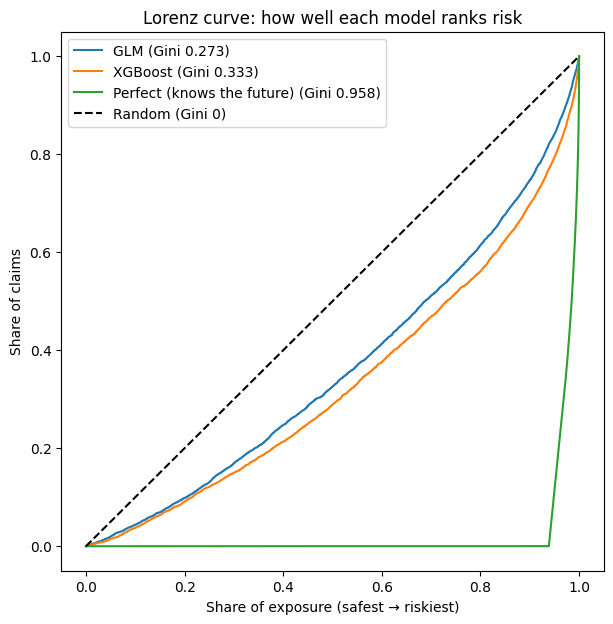

GLM      Gini = 0.273 | riskiest 10% make 25.3% of claims
XGBoost  Gini = 0.333 | riskiest 10% make 30.3% of claims


In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc

claims = test["ClaimNb"].to_numpy()
exposure = test["Exposure"].to_numpy()

def lorenz(pred):
    order = np.argsort(pred)                               # safest → riskiest
    cum_exposure = np.cumsum(exposure[order]) / exposure.sum()
    cum_claims = np.cumsum(claims[order]) / claims.sum()
    return cum_exposure, cum_claims

def gini(pred):
    x, y = lorenz(pred)
    return 1 - 2 * auc(x, y)

def top10_share(pred):
    x, y = lorenz(pred)
    return 1 - np.interp(0.9, x, y)                        # claims made by the riskiest 10%

models = {
    "GLM": glm.predict(test),
    "XGBoost": xgb_pred,
    "Perfect (knows the future)": claims / exposure,
}

plt.figure(figsize=(7, 7))
for name, pred in models.items():
    x, y = lorenz(pred)
    plt.plot(x, y, label=f"{name} (Gini {gini(pred):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (Gini 0)")
plt.xlabel("Share of exposure (safest → riskiest)")
plt.ylabel("Share of claims")
plt.title("Lorenz curve: how well each model ranks risk")
plt.legend()
plt.show()

for name, pred in list(models.items())[:2]:
    print(f"{name:8s} Gini = {gini(pred):.3f} | riskiest 10% make {top10_share(pred):.1%} of claims")

## 8. Explaining the model with SHAP
Which factors drive XGBoost's predictions, shown as multipliers on the predicted claim rate.

Average effect on the predicted rate (×):
BonusMalus    1.350
VehAge        1.218
DrivAge       1.151
Region        1.080
VehBrand      1.075
VehPower      1.072
Density       1.068
VehGas        1.027
Area          1.019
dtype: float32


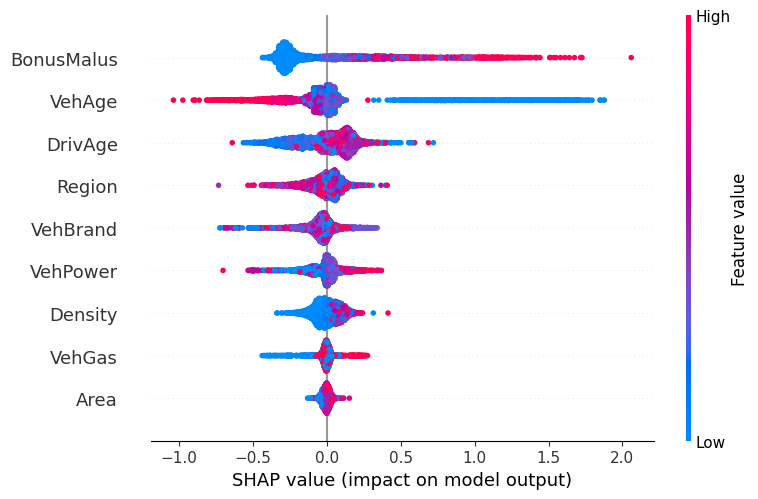

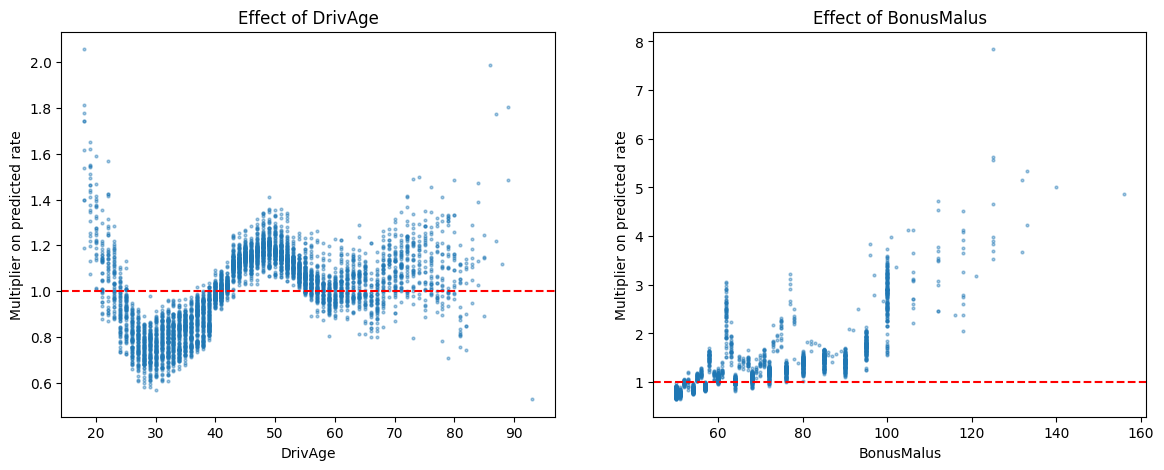

In [0]:
import shap

sample = test.sample(5000, random_state=42)
dm = xgb.DMatrix(sample[features], enable_categorical=True)
contribs = xgb_model.get_booster().predict(dm, pred_contribs=True)
shap_values = contribs[:, :-1]          # last column is the base rate

# 1. Which factors matter most? (average effect, shown as a multiplier)
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=features).sort_values(ascending=False)
print("Average effect on the predicted rate (×):")
print(np.exp(importance).round(3))

# 2. Overview plot: one dot per customer per factor
display_X = sample[features].copy()
for c in ["VehBrand", "VehGas", "Region", "Area"]:
    display_X[c] = display_X[c].cat.codes
shap.summary_plot(shap_values, display_X, show=True)

# 3. How driver age and BonusMalus change the rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["DrivAge", "BonusMalus"]):
    i = features.index(col)
    ax.scatter(sample[col], np.exp(shap_values[:, i]), s=4, alpha=0.4)
    ax.axhline(1, color="red", linestyle="--")
    ax.set_xlabel(col)
    ax.set_ylabel("Multiplier on predicted rate")
    ax.set_title(f"Effect of {col}")
plt.show()

## 9. Robustness check
SHAP showed XGBoost relying heavily on brand-new cars. Retrain without vehicle age to see how much of its gain depends on it.

In [0]:
features_nv = [f for f in features if f != "VehAge"]
fit_set, val_set = train_test_split(train, test_size=0.1, random_state=42)

xgb_nv = xgb.XGBRegressor(
    objective="count:poisson", n_estimators=2000, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, tree_method="hist",
    enable_categorical=True, early_stopping_rounds=50,
)
xgb_nv.fit(
    fit_set[features_nv], fit_set["Frequency"], sample_weight=fit_set["Exposure"],
    eval_set=[(val_set[features_nv], val_set["Frequency"])],
    sample_weight_eval_set=[val_set["Exposure"]], verbose=False,
)
pred_nv = xgb_nv.predict(test[features_nv])

for name, pred in [("GLM", glm.predict(test)), ("XGBoost", xgb_pred), ("XGBoost without VehAge", pred_nv)]:
    print(f"{name:24s} D² = {1 - deviance(pred) / dumb_dev:.2%} | Gini = {gini(pred):.3f}")

GLM                      D² = 4.53% | Gini = 0.273
XGBoost                  D² = 7.86% | Gini = 0.333
XGBoost without VehAge   D² = 4.84% | Gini = 0.291


Does the GLM catch up if it gets an explicit new-car flag?

In [0]:
train = train.assign(NewCar=(train["VehAge"] == 0).astype(int))
test = test.assign(NewCar=(test["VehAge"] == 0).astype(int))

glm_nc = make_pipeline(
    ColumnTransformer([
        ("age_bins", KBinsDiscretizer(n_bins=10, strategy="quantile"), ["DrivAge", "VehAge"]),
        ("categories", OneHotEncoder(handle_unknown="ignore"), ["VehBrand", "VehPower", "VehGas", "Region", "Area"]),
        ("numbers", StandardScaler(), ["BonusMalus_c", "LogDensity", "NewCar"]),
    ]),
    PoissonRegressor(alpha=1e-4, max_iter=1000),
)
glm_nc.fit(train, train["Frequency"], poissonregressor__sample_weight=train["Exposure"])
pred_glm_nc = glm_nc.predict(test)
print(f"GLM + new-car flag       D² = {1 - deviance(pred_glm_nc) / dumb_dev:.2%} | Gini = {gini(pred_glm_nc):.3f}")

/databricks/python/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


GLM + new-car flag       D² = 4.53% | Gini = 0.273


Which brands make up the new cars, and how often do they claim?

In [0]:
new = df[df["VehAge"] == 0]
g = new.groupby("VehBrand", observed=True).agg(
    policies=("IDpol", "count"), claims=("ClaimNb", "sum"), exposure=("Exposure", "sum")
)
g["frequency"] = g["claims"] / g["exposure"]
g["share_of_new_cars"] = g["policies"] / g["policies"].sum()
print(g.sort_values("policies", ascending=False).round(3))

b12 = df["VehBrand"] == "B12"
for label, mask in [("B12 new cars", b12 & (df["VehAge"] == 0)),
                    ("B12 older cars", b12 & (df["VehAge"] > 0)),
                    ("Other brands, new cars", ~b12 & (df["VehAge"] == 0))]:
    sub = df[mask]
    print(f"{label:24s} policies={len(sub):6d}  frequency={sub['ClaimNb'].sum() / sub['Exposure'].sum():.3f}")

          policies  claims  exposure  frequency  share_of_new_cars
VehBrand                                                          
B12          37069    4318  9559.617      0.452              0.642
B2            6207     264  2248.576      0.117              0.108
B1            5565     224  1908.609      0.117              0.096
B3            2887     137   959.213      0.143              0.050
B4            1226      62   398.524      0.156              0.021
B6            1105      50   377.262      0.133              0.019
B5            1088      45   381.584      0.118              0.019
B10           1053      41   352.846      0.116              0.018
B11            959      31   308.686      0.100              0.017
B13            430      23   149.279      0.154              0.007
B14            150      10    52.133      0.192              0.003
B12 new cars             policies= 37069  frequency=0.452
B12 older cars           policies=128955  frequency=0.082
Other brands,

Add a B12 × new-car interaction to the GLM: can one hand-built term recover XGBoost's gain?

In [0]:
train = train.assign(B12New=((train["VehBrand"] == "B12") & (train["VehAge"] == 0)).astype(int))
test = test.assign(B12New=((test["VehBrand"] == "B12") & (test["VehAge"] == 0)).astype(int))

glm_int = make_pipeline(
    ColumnTransformer([
        ("age_bins", KBinsDiscretizer(n_bins=10, strategy="quantile"), ["DrivAge", "VehAge"]),
        ("categories", OneHotEncoder(handle_unknown="ignore"), ["VehBrand", "VehPower", "VehGas", "Region", "Area"]),
        ("numbers", StandardScaler(), ["BonusMalus_c", "LogDensity", "B12New"]),
    ]),
    PoissonRegressor(alpha=1e-4, max_iter=1000),
)
glm_int.fit(train, train["Frequency"], poissonregressor__sample_weight=train["Exposure"])
pred_glm_int = glm_int.predict(test)

for name, pred in [("GLM", glm.predict(test)),
                   ("GLM + B12×new interaction", pred_glm_int),
                   ("XGBoost", xgb_pred)]:
    print(f"{name:28s} D² = {1 - deviance(pred) / dumb_dev:.2%} | Gini = {gini(pred):.3f}")

/databricks/python/lib/python3.12/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


GLM                          D² = 4.53% | Gini = 0.273
GLM + B12×new interaction    D² = 5.03% | Gini = 0.278
XGBoost                      D² = 7.86% | Gini = 0.333


## 10. Track every model in MLflow
Log parameters, D², Gini, top-10% claim share, balance, the Lorenz chart and the XGBoost model.

2026/11/18 11:22:36 INFO mlflow.tracking.fluent: Experiment with name '/Users/arihantgarg02@gmail.com/motor-claims-frequency' does not exist. Creating a new experiment.
2026/11/18 11:22:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-54cccc3c-3d75.cloud.databricks.com/ml/experiments/859006050225440/models/m-afdc8c4ffbf047c0823488d59aff1bd6?o=7474655892338716
2026/11/18 11:22:44 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


Logged 4 runs.


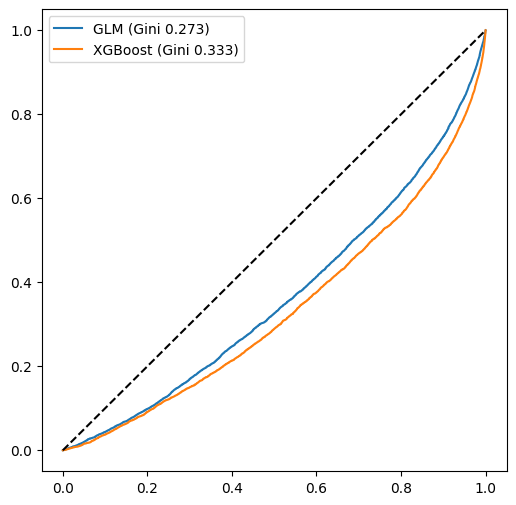

In [0]:
import mlflow

user = spark.sql("SELECT current_user()").first()[0]
mlflow.set_experiment(f"/Users/{user}/motor-claims-frequency")

runs = {
    "glm_baseline":        (glm.predict(test),  {"model": "Poisson GLM", "alpha": 1e-4, "age_bands": 10}),
    "glm_b12_interaction": (pred_glm_int,       {"model": "Poisson GLM", "alpha": 1e-4, "extra_feature": "B12 x new car"}),
    "xgb_poisson":         (xgb_pred,           {"model": "XGBoost", "objective": "count:poisson", "trees": xgb_model.best_iteration,
                                                 "learning_rate": 0.05, "max_depth": 5}),
    "xgb_no_vehage":       (pred_nv,            {"model": "XGBoost", "objective": "count:poisson", "dropped": "VehAge"}),
}

for run_name, (pred, params) in runs.items():
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metrics({
            "d2": 1 - deviance(pred) / dumb_dev,
            "gini": gini(pred),
            "top10_claim_share": top10_share(pred),
            "poisson_deviance": deviance(pred),
            "predicted_to_actual": (pred * test["Exposure"]).sum() / test["ClaimNb"].sum(),
        })
        if run_name == "xgb_poisson":
            mlflow.xgboost.log_model(xgb_model, "model")
            fig, ax = plt.subplots(figsize=(6, 6))
            for name, p in [("GLM", glm.predict(test)), ("XGBoost", xgb_pred)]:
                x, y = lorenz(p)
                ax.plot(x, y, label=f"{name} (Gini {gini(p):.3f})")
            ax.plot([0, 1], [0, 1], "k--")
            ax.legend()
            mlflow.log_figure(fig, "lorenz_curve.png")

print("Logged 4 runs.")